# Experimento 9 — Ablação: quanto cada grupo de atributos contribui?

**De onde viemos.** O modelo final foi construído passo a passo (experimentos 1 a 8): cada grupo de atributos foi avaliado no contexto do que já tinha entrado antes. Por isso, o ganho medido para cada grupo depende da ordem em que ele entrou. As contagens, por exemplo, só foram avaliadas depois de idade e ano.

**Pergunta:** no modelo completo, com todos os outros atributos presentes, quanto se perde ao retirar cada grupo?

**Ablação:** partimos do modelo completo, retiramos **um grupo de atributos por vez**, retreinamos o modelo do zero e comparamos o erro com o do modelo completo, nas mesmas partições.

### O que este experimento traz de novo

| | |
|---|---|
| **Ponto de partida** | Dois modelos completos: o boosting **sem nostalgia** (11 atributos, receita do notebook 10) e o boosting **com nostalgia** (12 atributos, modelo final do notebook 11). |
| **O que muda** | Em cada experimento, um grupo de atributos é retirado: médias, afinidade, gênero, idade, ano, contagens e, no modelo com nostalgia, a idade no lançamento. São 13 experimentos. |
| **Modelo** | O mesmo boosting, com a mesma busca interna de hiperparâmetros, retreinado do zero em cada experimento. |
| **Por que esta análise** | A construção incremental mede quanto cada grupo acrescenta dado o que veio antes. A ablação mede quanto cada grupo faz falta dado todo o resto, sem depender da ordem. Ela também verifica, no modelo final, a seleção de atributos que foi feita principalmente com a regressão. |
| **Por que dois modelos** | Comparar a ablação com e sem a idade no lançamento mostra, por outro ângulo, que informação a nostalgia acrescenta. |
| **Como ler o resultado** | Uma perda grande e significativa indica um grupo necessário. Uma perda perto de zero indica um grupo **redundante dado os outros**, não necessariamente inútil (ver o aviso abaixo). |

**Protocolo:** 5 dobras × 5 repetições, semente 2026; as mesmas partições dos experimentos anteriores, apenas `train.csv`, previsões cortadas em [0, 5]. Em cada experimento, os hiperparâmetros do boosting são escolhidos em 3 dobras internas de cada treino externo, com a grade do experimento 5. A perda de um grupo é a diferença média de $E_{CV}$ entre o modelo sem o grupo e o completo, avaliada pelo teste t corrigido (notebook 10, seção 3).

**Aviso sobre atributos relacionados.** Retirar um grupo não retira, necessariamente, a informação que ele carrega, quando outro atributo a contém:
- os **indicadores de gênero** saem, mas o gênero continua dentro da **afinidade**, que é a proporção do gênero *do filme* no histórico do usuário;
- a **idade** sai, mas, no modelo com nostalgia, continua recuperável: a idade no lançamento é `age − (2024 − release_year)`, então ela e o ano juntos determinam a idade. O mesmo vale para o **ano**, recuperável da idade e da idade no lançamento.

Por isso, uma perda pequena indica que o grupo é **redundante dado os outros**. Não retiramos grupos relacionados em conjunto: esta análise mede a contribuição **própria** de cada grupo.

**A ablação não muda o modelo final.** Se algum grupo parecer dispensável, não o retiramos: isso seria uma nova rodada de seleção olhando os mesmos dados, com mais otimismo. A ablação serve para explicar e verificar o modelo final.

O cálculo completo (15 modelos, cada um com busca interna nas 25 partições) está em `src/ablation.py` e leva cerca de 40 minutos. Aqui lemos os resultados gravados em `results/rodada_atual/ablacao*.csv`:

```bash
python -m src.ablation
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data' / 'train.csv').exists())
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

results = ROOT / 'results' / 'rodada_atual'
summary = pd.read_csv(results / 'ablacao.csv')
by_fold = pd.read_csv(results / 'ablacao_por_particao.csv')
selections = pd.read_csv(results / 'ablacao_selecoes.csv')
MODELS = summary['modelo completo'].unique().tolist()
LOSS = 'perda (E_CV sem o grupo − completo)'
print(MODELS)

['Boosting sem nostalgia (11 atributos)', 'Boosting com nostalgia (12 atributos)']


## 1. Resultados por modelo completo

A primeira linha de cada tabela é o modelo completo. Nas demais, a perda positiva significa que o erro **aumenta** sem o grupo. A última coluna conta em quantas das 25 partições o modelo completo teve menor $E_{CV}$.

In [2]:
columns = ['grupo retirado', 'n_atributos', 'RMSE OOF repetido', 'E_CV', 'E_in', 'gap E_CV − E_in',
           LOSS, 'IC inferior', 'IC superior', 'p-valor', 'partições em que o completo é melhor']
fmt = {c: '{:.4f}' for c in ['RMSE OOF repetido', 'E_CV', 'E_in', 'gap E_CV − E_in', LOSS, 'IC inferior', 'IC superior']}
fmt.update({'p-valor': '{:.2e}', 'partições em que o completo é melhor': '{:.0f}'})
for model in MODELS:
    print(model)
    table = summary[summary['modelo completo'] == model][columns]
    display(table.style.format(fmt, na_rep='—').hide(axis='index'))

Boosting sem nostalgia (11 atributos)


grupo retirado,n_atributos,RMSE OOF repetido,E_CV,E_in,gap E_CV − E_in,perda (E_CV sem o grupo − completo),IC inferior,IC superior,p-valor,partições em que o completo é melhor
nenhum (modelo completo),11,0.5449,0.5448,0.4315,0.1132,—,—,—,—,—
médias,9,0.9922,0.9919,0.9271,0.0648,0.4472,0.4206,0.4738,5.13e-22,25
afinidade,9,0.6718,0.6715,0.5617,0.1098,0.1267,0.1111,0.1423,9.38e-15,25
gênero,9,0.5488,0.5487,0.4380,0.1107,0.0039,-0.0010,0.0088,1.12e-01,20
idade,10,0.5929,0.5928,0.5205,0.0723,0.0480,0.0409,0.0552,5.85e-13,25
ano,9,0.5997,0.5996,0.5344,0.0652,0.0548,0.0471,0.0625,1.78e-13,25
contagens,9,0.5652,0.5650,0.4557,0.1093,0.0203,0.0130,0.0275,6.52e-06,25


Boosting com nostalgia (12 atributos)


grupo retirado,n_atributos,RMSE OOF repetido,E_CV,E_in,gap E_CV − E_in,perda (E_CV sem o grupo − completo),IC inferior,IC superior,p-valor,partições em que o completo é melhor
nenhum (modelo completo),12,0.5195,0.5194,0.4406,0.0788,—,—,—,—,—
médias,10,0.9763,0.9760,0.9086,0.0674,0.4566,0.4311,0.4822,1.17e-22,25
afinidade,10,0.6480,0.6478,0.5381,0.1097,0.1284,0.1149,0.1419,2.58e-16,25
gênero,10,0.5223,0.5222,0.4473,0.0748,0.0028,-0.0006,0.0061,1.04e-01,21
idade,11,0.5186,0.5185,0.4374,0.0810,-0.0009,-0.0041,0.0022,5.45e-01,10
ano,10,0.5180,0.5179,0.4317,0.0862,-0.0015,-0.0038,0.0007,1.66e-01,4
contagens,10,0.5450,0.5449,0.4658,0.0790,0.0255,0.0200,0.0310,1.17e-09,25
idade no lançamento,11,0.5449,0.5448,0.4315,0.1132,0.0253,0.0179,0.0328,2.86e-07,25


## 2. A perda de cada grupo, nos dois modelos

As barras horizontais são o intervalo de confiança de 95% da perda (teste t corrigido). Um intervalo que cruza o zero indica que a diferença não é significativa. O eixo está em escala simétrica-logarítmica: perto do zero ele é linear, e longe do zero comprime as perdas grandes, para que as pequenas também fiquem visíveis.

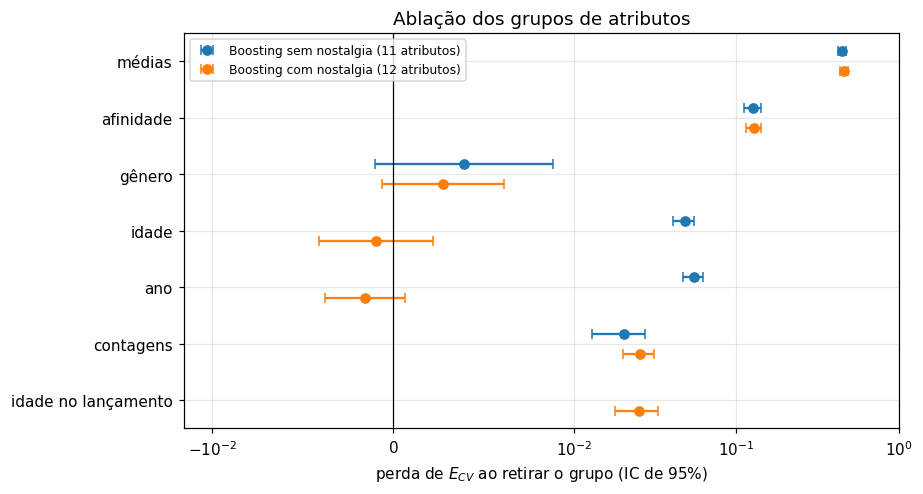

In [3]:
groups = [g for g in summary['grupo retirado'].unique() if g != 'nenhum (modelo completo)']
fig, ax = plt.subplots(figsize=(8.5, 4.6))
offsets = {MODELS[0]: -0.18, MODELS[1]: 0.18}
for i, model in enumerate(MODELS):
    part = summary[(summary['modelo completo'] == model) & summary[LOSS].notna()].set_index('grupo retirado')
    pos = [groups.index(g) + offsets[model] for g in part.index]
    ax.errorbar(part[LOSS], pos,
                xerr=[part[LOSS] - part['IC inferior'], part['IC superior'] - part[LOSS]],
                fmt='o', capsize=3, color=f'C{i}', label=model)
ax.axvline(0, color='k', lw=0.8)
ax.set_xscale('symlog', linthresh=0.01)
ax.set_xlim(-0.015, 1.0)
ax.set_yticks(range(len(groups)))
ax.set_yticklabels(groups)
ax.invert_yaxis()
ax.set(xlabel='perda de $E_{CV}$ ao retirar o grupo (IC de 95%)', title='Ablação dos grupos de atributos')
ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()

**Leitura**
- **As médias são, de longe, o grupo mais importante.** Sem elas, o erro sobe cerca de 0,45 estrela, nos dois modelos, e fica perto do erro da previsão constante (1,17). É a informação mais básica: quanto o usuário costuma dar e quanto o filme costuma receber.
- **A afinidade vem em segundo** (+0,13 nos dois modelos, 25 de 25 partições). Ela é a interação gênero × gosto do usuário, que motivou o experimento 2.
- **As contagens fazem falta nos dois modelos** (+0,020 sem nostalgia e +0,026 com nostalgia). Na construção incremental, elas quase não ajudavam a regressão, mas melhoravam o boosting. A ablação confirma que, no modelo final, elas trazem informação própria: o quanto confiar em cada média.
- **Os indicadores de gênero não são significativos em nenhum dos dois modelos** (+0,004 e +0,003; intervalos que cruzam o zero). É o caso previsto no aviso: o gênero continua presente dentro da afinidade.

## 3. Idade e ano: o que a nostalgia muda

É aqui que os dois modelos se diferenciam:

| Grupo retirado | Boosting sem nostalgia | Boosting com nostalgia |
|---|---:|---:|
| idade | +0,048 (25 de 25 partições) | −0,001 (não significativa) |
| ano | +0,055 (25 de 25 partições) | −0,002 (não significativa) |
| idade no lançamento | — | +0,025 (25 de 25 partições) |

- **Sem a nostalgia, idade e ano são indispensáveis.** O efeito de nostalgia depende dos dois juntos (a interação idade × ano). Sem um deles, o boosting não tem como reconstruí-lo.
- **Com a nostalgia, cada um deles, isoladamente, fica redundante.** A idade no lançamento já combina idade e ano. Junto com o atributo que sobra, ela permite recuperar o que foi retirado: idade = idade no lançamento + 2024 − ano. A perda é praticamente zero.
- **A idade no lançamento faz falta** (+0,025). Retirá-la devolve exatamente o boosting sem nostalgia (0,5449), o mesmo resultado do notebook 11.

Isso **não** quer dizer que idade e ano sejam inúteis no modelo final. Quer dizer que a informação deles está repetida em três atributos ligados por uma relação exata, e qualquer dois bastam. Nos dois casos, a perda não significativa é ligeiramente **negativa**: o modelo sem o atributo errou um pouco menos (sem o ano, em 21 das 25 partições). A diferença é pequena (−0,0015, IC [−0,004; 0,001]) e, como avisado, não usamos a ablação para trocar o modelo final.

## 4. Comparação com a construção incremental

| Grupo | Ganho ao entrar (construção incremental) | Perda ao sair (ablação, modelo final) |
|---|---|---|
| médias | 1,166 → 0,840 na regressão (experimento 1) | +0,457 |
| afinidade | −0,180 na regressão (experimento 2) | +0,128 |
| gênero | −0,004 na regressão (experimento 4) | +0,003 (n.s.) |
| idade e ano | −0,009 na regressão; −0,054 no boosting (experimento 7) | ≈ 0 cada um (redundantes com a idade no lançamento) |
| contagens | −0,001 na regressão; −0,020 no boosting (experimento 7) | +0,026 |
| idade no lançamento | −0,025 no boosting (experimento 8) | +0,025 |

As duas abordagens contam a mesma história para os grupos que carregam informação própria: médias, afinidade, contagens e idade no lançamento são necessárias, e os indicadores de gênero acrescentam pouco. A diferença está em idade e ano: na construção, eles trouxeram um ganho real ao entrar; no modelo final, depois que a idade no lançamento entrou, a informação deles passou a estar repetida. Só a ablação revela esse tipo de redundância.

## 5. Conclusões

1. **A ordem de importância no modelo final** é: médias (+0,46), afinidade (+0,13), contagens (+0,03) e idade no lançamento (+0,03). Todos esses grupos fazem falta nas 25 partições.
2. **Os indicadores de gênero são redundantes com a afinidade**, nos dois modelos.
3. **A nostalgia reorganiza a informação de idade e ano.** Sem ela, cada um custa cerca de 0,05 estrela ao sair. Com ela, cada um fica redundante, porque a idade no lançamento carrega a interação que antes exigia os dois.
4. **O modelo final não muda.** A ablação confirma que os grupos necessários estão presentes e explica por que alguns parecem dispensáveis. Simplificá-lo agora, com base nos mesmos dados, seria uma nova seleção sujeita a otimismo.

**Em termos do curso.** A ablação mede a contribuição de cada grupo para reduzir o **viés** do modelo: sem as médias ou sem a afinidade, o conjunto de hipóteses perde a capacidade de representar a estrutura principal dos dados, e o erro sobe muito. Já atributos redundantes quase não mudam o erro: retirá-los reduz a complexidade sem perder capacidade de representação.